In [1]:
import pandas as pd

df = pd.read_csv("../data/droplets_with_distance.csv")
print(df.shape)
print(df.isna().sum())
print(df.describe().round(2))

(1583, 9)
filename               0
id                     0
area_px                0
equiv_diameter_px      0
centroid_x             0
centroid_y             0
perimeter_px           0
circularity          950
dist_to_jet_px         0
dtype: int64
            id  area_px  equiv_diameter_px  centroid_x  centroid_y  \
count  1583.00  1583.00            1583.00     1583.00     1583.00   
mean     83.44    81.94               7.56      628.80      263.94   
std      64.72   175.53               6.87      366.11       63.19   
min       1.00     5.00               2.52        0.29       46.58   
25%      30.00     7.00               2.99      300.00      224.47   
50%      67.00    16.00               4.51      630.00      255.38   
75%     128.00    72.00               9.57      935.22      289.77   
max     281.00  2046.00              51.04     1277.73      455.50   

       perimeter_px  circularity  dist_to_jet_px  
count       1583.00       633.00         1583.00  
mean          34.96

In [2]:
from sklearn.model_selection import GroupShuffleSplit

df["near_jet"] = (df["dist_to_jet_px"] <= 5).astype(int)
features = ["area_px", "perimeter_px"]
X, y, groups = df[features], df["near_jet"], df["filename"]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(len(X_train), len(X_test))
print("frames in both sets:", set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))
print("share near jet: train", y_train.mean().round(2), "test", y_test.mean().round(2))

1119 464
frames in both sets: set()
share near jet: train 0.38 test 0.37


In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier

base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
deep = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
shallow = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_train, y_train)

for name, m in [
    ("always the majority class", base),
    ("unlimited-depth tree", deep),
    ("depth-3 tree", shallow),
]:
    print(
        f"{name}: train {m.score(X_train, y_train):.3f}, test {m.score(X_test, y_test):.3f}"
    )

always the majority class: train 0.625, test 0.631
unlimited-depth tree: train 0.856, test 0.528
depth-3 tree: train 0.666, test 0.616


In [4]:
import numpy as np

splitter10 = GroupShuffleSplit(n_splits=10, test_size=0.25, random_state=0)
scores = {"majority": [], "deep tree": [], "depth-3 tree": []}

for tr, te in splitter10.split(X, y, groups):
    Xtr, Xte, ytr, yte = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]
    for name, m in [
        ("majority", DummyClassifier(strategy="most_frequent")),
        ("deep tree", DecisionTreeClassifier(random_state=0)),
        ("depth-3 tree", DecisionTreeClassifier(max_depth=3, random_state=0)),
    ]:
        scores[name].append(m.fit(Xtr, ytr).score(Xte, yte))

for name, s in scores.items():
    print(
        f"{name}: mean test {np.mean(s):.3f}, std {np.std(s):.3f}, min {np.min(s):.3f}, max {np.max(s):.3f}"
    )

majority: mean test 0.642, std 0.021, min 0.614, max 0.673
deep tree: mean test 0.570, std 0.015, min 0.548, max 0.602
depth-3 tree: mean test 0.629, std 0.016, min 0.608, max 0.657


In [5]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

feat = pd.DataFrame(
    {
        "log_area": np.log(df["area_px"]),
        "log_dist": np.log(df["dist_to_jet_px"]),
    }
)
Z = StandardScaler().fit_transform(feat)

for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z)
    print(k, "clusters, silhouette", round(silhouette_score(Z, km.labels_), 3))

2 clusters, silhouette 0.42
3 clusters, silhouette 0.453
4 clusters, silhouette 0.46
5 clusters, silhouette 0.42
6 clusters, silhouette 0.424


In [6]:
K = 3
km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(Z)
df["cluster"] = km.labels_

print(
    df.groupby("cluster")
    .agg(
        n=("id", "size"),
        median_area=("area_px", "median"),
        median_dist=("dist_to_jet_px", "median"),
    )
    .round(1)
)

           n  median_area  median_dist
cluster                               
0        653          8.0          3.0
1        483         13.0         36.8
2        447        157.0         13.8


In [7]:
from sklearn.metrics import adjusted_rand_score

base = KMeans(n_clusters=3, n_init=10, random_state=0).fit(Z).labels_
for seed in [1, 2, 3]:
    other = KMeans(n_clusters=3, n_init=10, random_state=seed).fit(Z).labels_
    print("seed", seed, "vs seed 0:", round(adjusted_rand_score(base, other), 3))

frames = df["filename"].unique()
half = set(
    np.random.default_rng(0).choice(frames, size=len(frames) // 2, replace=False)
)
mask = df["filename"].isin(half).values
km_half = KMeans(n_clusters=3, n_init=10, random_state=0).fit(Z[mask])
print(
    "held-out frames:",
    round(adjusted_rand_score(base[~mask], km_half.predict(Z[~mask])), 3),
)

seed 1 vs seed 0: 1.0
seed 2 vs seed 0: 1.0
seed 3 vs seed 0: 1.0
held-out frames: 0.951


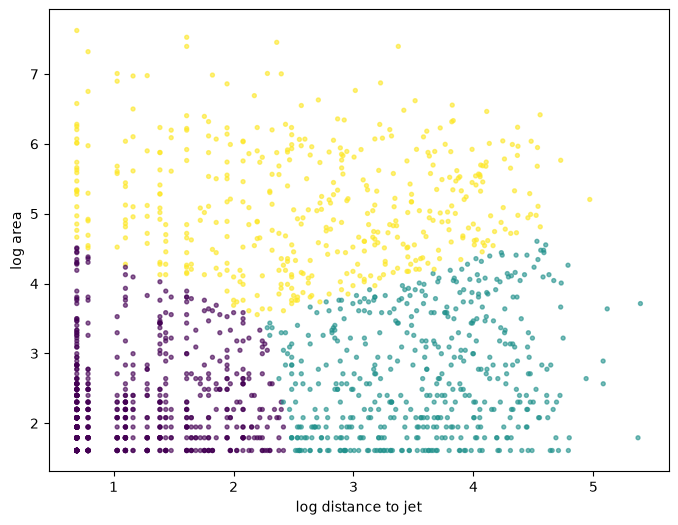

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(feat["log_dist"], feat["log_area"], c=df["cluster"], s=8, alpha=0.6)
plt.xlabel("log distance to jet")
plt.ylabel("log area")
plt.savefig("../data/clusters.png", dpi=150, bbox_inches="tight")
plt.show()